In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor


In [2]:
DATA_PATH = Path("data/raw")
files = {
    "actual_matrix": "actual_matrix.csv",
    "catalog": "catalog.csv",
    "discounts_history": "discounts_history.csv",
    "markdowns": "markdowns.csv",
    "online": "online.csv",
    "price_history": "price_history.csv",
    "sales": "sales.csv",
    "stores": "stores.csv"
}

datasets = {}

for name, filename in files.items():
    datasets[name] = pd.read_csv(DATA_PATH / filename)

In [3]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

actual_matrix: (35202, 4)
catalog: (219810, 9)
discounts_history: (3746744, 9)
markdowns: (8979, 7)
online: (1123412, 7)
price_history: (698626, 6)
sales: (7432685, 7)
stores: (4, 6)


In [4]:
for name, df in datasets.items():
    print(f"\n{'=' * 70}")
    print(f"DATASET: {name}")
    print(f"{'=' * 70}")
    print(df.columns.tolist())


DATASET: actual_matrix
['Unnamed: 0', 'item_id', 'date', 'store_id']

DATASET: catalog
['Unnamed: 0', 'item_id', 'dept_name', 'class_name', 'subclass_name', 'item_type', 'weight_volume', 'weight_netto', 'fatness']

DATASET: discounts_history
['Unnamed: 0', 'date', 'item_id', 'sale_price_before_promo', 'sale_price_time_promo', 'promo_type_code', 'doc_id', 'number_disc_day', 'store_id']

DATASET: markdowns
['Unnamed: 0', 'date', 'item_id', 'normal_price', 'price', 'quantity', 'store_id']

DATASET: online
['Unnamed: 0', 'date', 'item_id', 'quantity', 'price_base', 'sum_total', 'store_id']

DATASET: price_history
['Unnamed: 0', 'date', 'item_id', 'price', 'code', 'store_id']

DATASET: sales
['Unnamed: 0', 'date', 'item_id', 'quantity', 'price_base', 'sum_total', 'store_id']

DATASET: stores
['Unnamed: 0', 'store_id', 'division', 'format', 'city', 'area']


In [5]:
for name, df in datasets.items():
    print(f"\n{'=' * 70}")
    print(f"DATASET: {name}")
    print(f"{'=' * 70}")
    display(df.head())


DATASET: actual_matrix


,Unnamed: 0,item_id,date,store_id
0,0,c578da8e8841,2019-10-17,1
1,1,4dd2b686802c,2019-10-17,1
2,2,16ade2e3fca9,2019-10-17,1
3,3,f4eb16dab09e,2019-10-17,1
4,4,ab1384c2af6d,2020-05-31,1



DATASET: catalog


,Unnamed: 0,item_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness
0,0,da17e2d5feda,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,БУМАЖНАЯ ПРОДУКЦИЯ,ВЛАЖНЫЕ САЛФЕТКИ,NaN,150.0,NaN,NaN
1,1,614de2b96018,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN
2,2,0c1f1f3e3e11,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,NaN,NaN,NaN
3,3,71a7fa99f005,ТОВАРЫ ДЛЯ ДОМА,ПОСУДА,КУХОННАЯ ПОСУДА,NaN,NaN,NaN,NaN
4,4,ec1bd4d59fe9,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN



DATASET: discounts_history


,Unnamed: 0,date,item_id,sale_price_before_promo,sale_price_time_promo,promo_type_code,doc_id,number_disc_day,store_id
0,3648316,2022-08-28,cde97a9ec3ef,729.9,669.9,6.0,89ea9f0c-1c08-11ed-ad4d-005056861040,13.0,1
1,3648317,2022-08-28,2906fbc9e11c,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
2,3648318,2022-08-28,c48c3a3d8c01,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
3,3648319,2022-08-28,f85243ca61e6,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
4,3648320,2022-08-28,27ce75534065,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1


... (6 outputs left out)


DATASET: sales


,Unnamed: 0,date,item_id,quantity,price_base,sum_total,store_id
0,0,2023-08-04,293375605257,1.000,47.86,47.86,1
1,1,2023-08-04,a66fdf2c0ae7,3.000,49.60,148.80,1
2,2,2023-08-04,daa46ef49b7a,0.822,379.00,311.54,1
3,3,2023-08-04,a3b49c1bf758,1.000,129.00,129.00,1
4,4,2023-08-04,ab611c5cef62,7.000,79.90,559.30,1



DATASET: stores


,Unnamed: 0,store_id,division,format,city,area
0,0,4,Div1,MaxiEuro,City3,1887
1,1,3,Div2,Format-7 express,City2,109
2,2,2,Div2,Format-6,City1,210
3,3,1,Div1,Format-1,City1,1500


In [6]:
sales = datasets["sales"].copy()

print("Dimensiones:", sales.shape)

print("\nTipos de datos:")
print(sales.dtypes)

print("\nValores nulos:")
print(sales.isna().sum())

print("\nDuplicados completos:")
print(sales.duplicated().sum())

Dimensiones: (7432685, 7)

Tipos de datos:
Unnamed: 0      int64
date           object
item_id        object
quantity      float64
price_base    float64
sum_total     float64
store_id        int64
dtype: object

Valores nulos:
Unnamed: 0    0
date          0
item_id       0
quantity      0
price_base    0
sum_total     0
store_id      0
dtype: int64

Duplicados completos:
0


In [7]:
print("\nRango de fechas:")
print("Mínima:", sales["date"].min())
print("Máxima:", sales["date"].max())


Rango de fechas:
Mínima: 2022-08-28
Máxima: 2024-09-26


In [8]:
key_cols = ["date", "item_id", "store_id"]

duplicates_key = sales.duplicated(
    subset=key_cols,
    keep=False
)

print(
    f"\nFilas con combinación "
    f"date + item_id + store_id duplicada: "
    f"{duplicates_key.sum():,}"
)


Filas con combinación date + item_id + store_id duplicada: 0


In [9]:
print("\nEjemplos de posibles duplicados:")

display(
    sales.loc[duplicates_key]
         .sort_values(key_cols)
         .head(20)
)


Ejemplos de posibles duplicados:


,Unnamed: 0,date,item_id,quantity,price_base,sum_total,store_id


In [10]:
price_history = datasets["price_history"].copy()

print("Valores de price = 0:")
print((price_history["price"] == 0).sum())

print("\nValores de code = 9999999999:")
print((price_history["code"] == 9999999999).sum())

print("\nValores nulos:")
print(price_history.isna().sum())

Valores de price = 0:
61659

Valores de code = 9999999999:
38554

Valores nulos:
Unnamed: 0    0
date          0
item_id       0
price         0
code          0
store_id      0
dtype: int64


In [11]:
print("\nEstadísticas de price:")
print(price_history["price"].describe())


Estadísticas de price:
count    6.986260e+05
mean     6.737037e+02
std      2.013703e+05
min      0.000000e+00
25%      6.590000e+01
50%      1.499000e+02
75%      3.599000e+02
max      1.184967e+08
Name: price, dtype: float64


In [12]:
print("Estadísticas de quantity:")
print(sales["quantity"].describe())

print("\nValores de quantity <= 0:")
print((sales["quantity"] <= 0).sum())

print("\nValores de quantity == 0:")
print((sales["quantity"] == 0).sum())

print("\nValores de quantity < 0:")
print((sales["quantity"] < 0).sum())

print("\nEstadísticas de price_base:")
print(sales["price_base"].describe())

print("\nEstadísticas de sum_total:")
print(sales["sum_total"].describe())

Estadísticas de quantity:
count    7.432685e+06
mean     5.642398e+00
std      2.740466e+01
min     -5.000000e+02
25%      1.000000e+00
50%      2.000000e+00
75%      4.672000e+00
max      4.952000e+03
Name: quantity, dtype: float64

Valores de quantity <= 0:
3598

Valores de quantity == 0:
2438

Valores de quantity < 0:
1160

Estadísticas de price_base:
count    7.432685e+06
mean     2.075824e+02
std      3.372886e+02
min     -2.167667e+04
25%      6.000000e+01
50%      1.099000e+02
75%      1.999000e+02
max      2.899990e+04
Name: price_base, dtype: float64

Estadísticas de sum_total:
count    7.432685e+06
mean     7.612796e+02
std      4.789478e+03
min     -2.041080e+04
25%      1.279000e+02
50%      2.596000e+02
75%      5.990000e+02
max      6.865242e+05
Name: sum_total, dtype: float64


In [13]:
sales["calculated_total"] = (
    sales["quantity"] * sales["price_base"]
)

sales["total_difference"] = (
    sales["sum_total"] - sales["calculated_total"]
)

print(
    sales["total_difference"].describe()
)

print(
    "Diferencias mayores a 0.01:",
    (sales["total_difference"].abs() > 0.01).sum()
)

count    7.432685e+06
mean    -9.236540e-03
std      2.822074e+00
min     -2.788000e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.399000e+03
Name: total_difference, dtype: float64
Diferencias mayores a 0.01: 1041252


In [14]:
sales["date"] = pd.to_datetime(sales["date"])

print("Fecha mínima:", sales["date"].min())
print("Fecha máxima:", sales["date"].max())
print("Número de días:", sales["date"].nunique())


sales_by_date = (
    sales.groupby("date")
    .agg(
        total_quantity=("quantity", "sum"),
        transactions=("item_id", "count")
    )
    .reset_index()
)

display(sales_by_date.head())

Fecha mínima: 2022-08-28 00:00:00
Fecha máxima: 2024-09-26 00:00:00
Número de días: 761


,date,total_quantity,transactions
0,2022-08-28,35616.579,6628
1,2022-08-29,41935.293,7137
2,2022-08-30,40996.841,7222
3,2022-08-31,43387.136,7281
4,2022-09-01,50626.987,7668


In [15]:
#Cantidades negativas
negative_quantity = sales[sales["quantity"] < 0]

print("Registros con quantity negativa:", len(negative_quantity))

display(
    negative_quantity[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].head(20)
)

print("Distribución de cantidades negativas:")
print(
    negative_quantity["quantity"]
    .value_counts()
    .sort_index()
    .head(20)
)

Registros con quantity negativa: 1160


,date,item_id,quantity,price_base,sum_total,store_id
2213,2023-08-04,eabcd9da5a8e,-1.430,4.90,-7.00,1
4956,2023-08-04,8d0a2068aa75,-4.000,126.00,-504.00,1
9957,2023-08-08,2f57275be77b,-1.000,2000.00,-2000.00,1
14012,2023-08-08,95879f411e24,-1.000,115.94,-115.94,1
16440,2023-08-09,4e0ef6cff251,-0.685,-32.39,22.19,1
30867,2023-08-17,f667cbad9c1b,-1.000,699.00,-699.00,1
32257,2023-08-17,f2db8426e5e0,-1.000,74.00,-74.00,1
43169,2023-08-20,d2a723103e16,-30.000,10.00,-300.00,1
43183,2023-08-20,6d09a07dac9a,-1.000,1490.00,-1490.00,1
45817,2023-08-20,af37779ed8b0,-1.000,89.00,-89.00,1


Distribución de cantidades negativas:
quantity
-500.0     2
-408.0     1
-350.0     1
-300.0     2
-292.0     1
-220.0     1
-200.0     7
-182.0     1
-180.0     1
-160.0     1
-150.0     5
-130.0     3
-100.0    21
-91.0      1
-60.0      2
-50.0     29
-38.0      1
-30.0     12
-28.0      1
-26.0      1
Name: count, dtype: int64


In [16]:
#quantity = 0
zero_quantity = sales[sales["quantity"] == 0]

print("Registros con quantity = 0:", len(zero_quantity))

display(
    zero_quantity[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].head(20)
)

Registros con quantity = 0: 2438


,date,item_id,quantity,price_base,sum_total,store_id
1167,2023-08-04,fdba6ef80c19,0.0,0.0,0.00,1
1819,2023-08-04,e30114c99ce6,0.0,0.0,0.00,1
3346,2023-08-04,774d0ac89f51,0.0,0.0,0.00,1
4420,2023-08-04,fbc24e98a14e,0.0,0.0,19.80,1
5644,2023-08-07,76ad74eb6daa,0.0,0.0,74.00,1
9511,2023-08-07,5ada19122e86,0.0,0.0,0.90,1
12365,2023-08-08,ecabaae65646,0.0,0.0,0.90,1
19400,2023-08-15,4873bdc0d5c5,0.0,0.0,0.90,1
20185,2023-08-15,4b797bb271c0,0.0,0.0,0.90,1
21446,2023-08-15,a22cf9a0623d,0.0,0.0,0.00,1


In [17]:
#precios negativos
negative_price = sales[sales["price_base"] < 0]

print("Registros con price_base negativo:", len(negative_price))

display(
    negative_price[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].head(20)
)

print(
    sales.loc[
        sales["price_base"] <= 0,
        "price_base"
    ].describe()
)


Registros con price_base negativo: 67


,date,item_id,quantity,price_base,sum_total,store_id
16440,2023-08-09,4e0ef6cff251,-0.685,-32.39,22.19,1
81056,2023-08-27,9fb64cd80a25,-0.216,-4494.95,970.91,1
514645,2023-11-26,ffc6200feffd,-0.150,-2338.00,350.70,1
636568,2023-12-22,4b797bb271c0,1.000,-20.20,-20.20,1
1156561,2024-04-05,303f02044ca2,2.000,-50.05,-100.10,1
1285525,2024-04-29,a30fe89866ac,-0.255,-823.41,209.97,1
1379075,2024-05-17,900b8eb2d0e4,-0.415,-9.08,3.77,1
1384680,2024-05-18,45ec31162fbd,1.000,-551.00,-551.00,1
1402527,2024-05-22,f6a2e81f6979,-0.094,-3867.45,363.54,1
1429057,2024-05-27,ae6a88fa8d71,0.032,-1637.81,-52.41,1


count     8093.000000
mean       -12.509685
std        331.898137
min     -21676.670000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.000000
Name: price_base, dtype: float64


In [18]:
#precios extremadamente altos
q1 = sales["price_base"].quantile(0.25)
q3 = sales["price_base"].quantile(0.75)

iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper bound:", upper_bound)

print(
    "Valores por encima del límite:",
    (sales["price_base"] > upper_bound).sum()
)

display(
    sales.loc[
        sales["price_base"] > upper_bound,
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ]
    .sort_values("price_base", ascending=False)
    .head(20)
)

Q1: 60.0
Q3: 199.9
IQR: 139.9
Upper bound: 409.75
Valores por encima del límite: 870064


,date,item_id,quantity,price_base,sum_total,store_id
6208293,2024-02-20,33dd4df7022d,1.0,28999.9,28999.9,4
5950957,2023-12-31,33dd4df7022d,1.0,28999.9,28999.9,4
5887744,2023-12-20,33dd4df7022d,1.0,28999.9,28999.9,4
5390530,2024-08-20,33dd4df7022d,1.0,26490.0,26490.0,3
1598320,2024-06-29,33dd4df7022d,1.0,26490.0,26490.0,1
1942223,2024-09-05,33dd4df7022d,1.0,26490.0,26490.0,1
1876597,2024-08-23,33dd4df7022d,1.0,26490.0,26490.0,1
1552159,2024-06-20,33dd4df7022d,1.0,25990.0,25990.0,1
1481125,2024-06-06,33dd4df7022d,1.0,25690.0,25690.0,1
923896,2024-02-19,33dd4df7022d,1.0,25690.0,25690.0,1


In [19]:
#investigar sum_total
print("Estadísticas completas de sum_total:")
print(sales["sum_total"].describe())

print(
    "\nValores negativos:",
    (sales["sum_total"] < 0).sum()
)

print(
    "Valores iguales a 0:",
    (sales["sum_total"] == 0).sum()
)

Estadísticas completas de sum_total:
count    7.432685e+06
mean     7.612796e+02
std      4.789478e+03
min     -2.041080e+04
25%      1.279000e+02
50%      2.596000e+02
75%      5.990000e+02
max      6.865242e+05
Name: sum_total, dtype: float64

Valores negativos: 1610
Valores iguales a 0: 6593


In [20]:
price_stats = (
    sales
    .groupby("item_id")["price_base"]
    .agg(
        price_min="min",
        price_median="median",
        price_max="max",
        price_mean="mean",
        price_std="std",
        observations="count"
    )
    .reset_index()
)

display(
    price_stats
    .sort_values("price_max", ascending=False)
    .head(20)
)

,item_id,price_min,price_median,price_max,price_mean,price_std,observations
5751,33dd4df7022d,17599.92,25690.00,28999.9,24925.312941,3167.859060,17
21022,be8613b521dc,0.00,18899.62,19999.0,11399.374286,10055.690772,7
2268,1471e5bdd11f,19890.00,19890.00,19890.0,19890.000000,0.000000,7
13459,79321e8badfb,17999.90,17999.90,18999.0,18332.933333,576.830654,3
24524,dee614a9ea4d,8999.00,14099.58,17990.0,13277.636923,3851.299246,13
17968,a1a5594a74db,17599.90,17599.90,17599.9,17599.900000,NaN,1
21130,bf7ae39ed214,12999.90,13999.90,16999.9,14199.900000,1643.167673,5
13188,76dc491fa971,7990.00,14990.00,16990.0,14390.308000,1687.867901,50
15179,88e55870b960,13990.90,15990.00,16590.0,15430.360000,1336.676566,5
27167,f6a2e81f6979,-9782.80,599.90,14995.0,625.603432,636.917412,845


In [21]:
item_id = "33dd4df7022d"

display(
    sales.loc[
        sales["item_id"] == item_id,
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ]
    .sort_values("date")
    .head(30)
)

display(
    datasets["catalog"].loc[
        datasets["catalog"]["item_id"] == item_id
    ]
)

,date,item_id,quantity,price_base,sum_total,store_id
5468858,2022-10-02,33dd4df7022d,1.0,21999.90,21999.90,3
2487935,2022-12-02,33dd4df7022d,3.0,20990.00,62970.00,1
5568346,2022-12-31,33dd4df7022d,1.0,21999.90,21999.90,3
5630683,2023-02-28,33dd4df7022d,1.0,21999.90,21999.90,3
5694668,2023-04-24,33dd4df7022d,1.0,17599.92,17599.92,3
5887744,2023-12-20,33dd4df7022d,1.0,28999.90,28999.90,4
5950957,2023-12-31,33dd4df7022d,1.0,28999.90,28999.90,4
923896,2024-02-19,33dd4df7022d,1.0,25690.00,25690.00,1
6208293,2024-02-20,33dd4df7022d,1.0,28999.90,28999.90,4
1363604,2024-05-14,33dd4df7022d,1.0,23121.00,23121.00,1


,Unnamed: 0,item_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness
25729,25729,33dd4df7022d,КОНЬЯК,ИМПОРТ,КОНЬЯК,Коньяк,0.7,0.7,NaN


In [22]:
print("Productos:", sales["item_id"].nunique())
print("Tiendas:", sales["store_id"].nunique())

print(
    "Productos con al menos una venta:",
    sales.groupby("item_id").ngroups
)

Productos: 28182
Tiendas: 4
Productos con al menos una venta: 28182


In [23]:
zero_price = sales[sales["price_base"] == 0]

print("Registros con price_base = 0:", len(zero_price))

print("\nQuantity:")
print(zero_price["quantity"].describe())

print("\nSum_total:")
print(zero_price["sum_total"].describe())

display(
    zero_price[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].head(30)
)

Registros con price_base = 0: 8026

Quantity:
count    8026.000000
mean        0.992397
std         4.224011
min        -1.000000
25%         0.000000
50%         1.000000
75%         1.000000
max       360.000000
Name: quantity, dtype: float64

Sum_total:
count    8026.000000
mean       -7.991976
std        85.482568
min     -2788.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1399.000000
Name: sum_total, dtype: float64


,date,item_id,quantity,price_base,sum_total,store_id
1167,2023-08-04,fdba6ef80c19,0.000,0.0,0.0,1
1819,2023-08-04,e30114c99ce6,0.000,0.0,0.0,1
2301,2023-08-04,779193b74e9b,1.000,0.0,0.0,1
3346,2023-08-04,774d0ac89f51,0.000,0.0,0.0,1
4420,2023-08-04,fbc24e98a14e,0.000,0.0,19.8,1
5644,2023-08-07,76ad74eb6daa,0.000,0.0,74.0,1
5686,2023-08-07,95833d99e8e4,1.000,0.0,0.0,1
6905,2023-08-07,d23debae34e6,1.000,0.0,0.0,1
9322,2023-08-07,245abe1b167b,1.000,0.0,0.0,1
9393,2023-08-07,d7202fe81b76,1.000,0.0,0.0,1


In [24]:
zero_price = sales[sales["price_base"] == 0].copy()

print("Cantidad > 0:")
print((zero_price["quantity"] > 0).sum())

print("\nCantidad = 0:")
print((zero_price["quantity"] == 0).sum())

print("\nCantidad < 0:")
print((zero_price["quantity"] < 0).sum())

print("\nQuantity > 0 y sum_total != 0:")
print(
    ((zero_price["quantity"] > 0) &
     (zero_price["sum_total"] != 0)).sum()
)

print("\nQuantity = 0 y sum_total != 0:")
print(
    ((zero_price["quantity"] == 0) &
     (zero_price["sum_total"] != 0)).sum()
)

display(
    zero_price[
        (zero_price["quantity"] > 0) &
        (zero_price["sum_total"] != 0)
    ][
        ["date", "item_id", "quantity", "price_base", "sum_total", "store_id"]
    ].head(30)
)

Cantidad > 0:
5580

Cantidad = 0:
2438

Cantidad < 0:
8

Quantity > 0 y sum_total != 0:
28

Quantity = 0 y sum_total != 0:
1405


,date,item_id,quantity,price_base,sum_total,store_id
1024283,2024-03-09,b5aac3497e3f,3.0,0.0,0.01,1
1069020,2024-03-19,cb2c753ba7b5,7.0,0.0,0.02,1
1275515,2024-04-27,b5aac3497e3f,4.0,0.0,0.01,1
1674735,2024-07-15,cb2c753ba7b5,6.0,0.0,0.01,1
1744290,2024-07-28,b5aac3497e3f,6.0,0.0,0.02,1
1982650,2024-09-13,b5aac3497e3f,5.0,0.0,0.01,1
2074286,2022-09-02,b5aac3497e3f,3.0,0.0,0.01,1
2831026,2023-02-13,cb2c753ba7b5,17.0,0.0,0.07,1
3095666,2023-04-10,cb2c753ba7b5,3.0,0.0,0.01,1
3391190,2023-06-10,cb2c753ba7b5,8.0,0.0,0.03,1


In [25]:
negative_price = sales[sales["price_base"] < 0].copy()

print("Registros con price_base < 0:", len(negative_price))

print("\nDistribución de quantity:")
print(negative_price["quantity"].describe())

print("\nDistribución de sum_total:")
print(negative_price["sum_total"].describe())

print("\nQuantity > 0:")
print((negative_price["quantity"] > 0).sum())

print("\nQuantity = 0:")
print((negative_price["quantity"] == 0).sum())

print("\nQuantity < 0:")
print((negative_price["quantity"] < 0).sum())

display(
    negative_price[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].sort_values("price_base").head(30)
)

Registros con price_base < 0: 67

Distribución de quantity:
count    67.000000
mean      0.197701
std       1.064786
min      -0.830000
25%      -0.402500
50%      -0.115000
75%       1.000000
max       5.000000
Name: quantity, dtype: float64

Distribución de sum_total:
count      67.00000
mean       15.09597
std       649.91218
min     -4730.60000
25%       -41.25500
50%         0.93000
75%       212.96000
max       970.91000
Name: sum_total, dtype: float64

Quantity > 0:
26

Quantity = 0:
0

Quantity < 0:
41


,date,item_id,quantity,price_base,sum_total,store_id
7019917,2024-07-15,eabcd9da5a8e,-0.021,-21676.67,455.21,4
5968928,2024-01-04,a2bd8ba522a2,0.006,-10390.00,-62.34,4
1894226,2024-08-27,f6a2e81f6979,-0.050,-9782.80,489.14,1
6796098,2024-06-05,7a675a977b18,-0.092,-9483.80,872.51,4
81056,2023-08-27,9fb64cd80a25,-0.216,-4494.95,970.91,1
3604803,2023-07-25,94a53942676c,-0.099,-4480.81,443.60,1
3644829,2023-08-02,9437eafe7bae,-0.057,-4114.91,234.55,1
1969927,2024-09-11,4c6621e9db12,0.006,-3933.33,-23.60,1
1402527,2024-05-22,f6a2e81f6979,-0.094,-3867.45,363.54,1
3953938,2024-02-13,7a675a977b18,-0.265,-2375.66,629.55,2


In [26]:
negative_quantity = sales[sales["quantity"] < 0].copy()

print("Registros con quantity < 0:", len(negative_quantity))

print("\nDistribución de quantity:")
print(negative_quantity["quantity"].describe())

print("\nDistribución de price_base:")
print(negative_quantity["price_base"].describe())

print("\nDistribución de sum_total:")
print(negative_quantity["sum_total"].describe())

print("\nprice_base < 0:")
print((negative_quantity["price_base"] < 0).sum())

print("\nprice_base = 0:")
print((negative_quantity["price_base"] == 0).sum())

print("\nprice_base > 0:")
print((negative_quantity["price_base"] > 0).sum())

display(
    negative_quantity[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ]
    .sort_values("quantity")
    .head(30)
)

Registros con quantity < 0: 1160

Distribución de quantity:
count    1160.000000
mean       -9.821413
std        39.853714
min      -500.000000
25%        -1.000000
50%        -1.000000
75%        -0.742000
max        -0.001000
Name: quantity, dtype: float64

Distribución de price_base:
count     1160.000000
mean       541.815793
std       1288.515434
min     -21676.670000
25%         89.880000
50%        269.900000
75%        779.210000
max      14990.000000
Name: price_base, dtype: float64

Distribución de sum_total:
count     1160.000000
mean      -675.486310
std       1373.854107
min     -20410.800000
25%       -722.250000
50%       -273.940000
75%       -119.000000
max        970.910000
Name: sum_total, dtype: float64

price_base < 0:
41

price_base = 0:
8

price_base > 0:
1111


,date,item_id,quantity,price_base,sum_total,store_id
70371,2023-08-25,d2a723103e16,-500.0,10.00,-5000.00,1
2610902,2022-12-28,d2a723103e16,-500.0,10.00,-5000.00,1
2456135,2022-11-25,b0d24502fb66,-408.0,7.27,-2967.70,1
2874632,2023-02-23,d2a723103e16,-350.0,10.00,-3500.00,1
6478405,2024-04-10,d2a723103e16,-300.0,10.00,-3000.00,4
3329188,2023-05-28,d2a723103e16,-300.0,10.00,-3000.00,1
5197845,2024-02-29,8250099a8aff,-292.0,69.90,-20410.80,3
2279813,2022-10-18,d2a723103e16,-220.0,10.00,-2200.00,1
865811,2024-02-07,d2a723103e16,-200.0,10.00,-2000.00,1
940608,2024-02-22,d2a723103e16,-200.0,10.00,-2000.00,1


In [27]:
zero_quantity = sales[sales["quantity"] == 0].copy()

print("Registros con quantity = 0:", len(zero_quantity))

print("\nprice_base < 0:")
print((zero_quantity["price_base"] < 0).sum())

print("\nprice_base = 0:")
print((zero_quantity["price_base"] == 0).sum())

print("\nprice_base > 0:")
print((zero_quantity["price_base"] > 0).sum())

print("\nsum_total = 0:")
print((zero_quantity["sum_total"] == 0).sum())

print("\nsum_total != 0:")
print((zero_quantity["sum_total"] != 0).sum())

display(
    zero_quantity[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].head(30)
)


Registros con quantity = 0: 2438

price_base < 0:
0

price_base = 0:
2438

price_base > 0:
0

sum_total = 0:
1033

sum_total != 0:
1405


,date,item_id,quantity,price_base,sum_total,store_id
1167,2023-08-04,fdba6ef80c19,0.0,0.0,0.00,1
1819,2023-08-04,e30114c99ce6,0.0,0.0,0.00,1
3346,2023-08-04,774d0ac89f51,0.0,0.0,0.00,1
4420,2023-08-04,fbc24e98a14e,0.0,0.0,19.80,1
5644,2023-08-07,76ad74eb6daa,0.0,0.0,74.00,1
9511,2023-08-07,5ada19122e86,0.0,0.0,0.90,1
12365,2023-08-08,ecabaae65646,0.0,0.0,0.90,1
19400,2023-08-15,4873bdc0d5c5,0.0,0.0,0.90,1
20185,2023-08-15,4b797bb271c0,0.0,0.0,0.90,1
21446,2023-08-15,a22cf9a0623d,0.0,0.0,0.00,1


In [28]:
print("Total registros originales:", len(sales))

print("Quantity > 0:", (sales["quantity"] > 0).sum())

print("Quantity = 0:", (sales["quantity"] == 0).sum())

print("Quantity < 0:", (sales["quantity"] < 0).sum())

print(
    "\n% de registros que conservaremos:",
    round((sales["quantity"] > 0).mean() * 100, 4),
)

print(
    "% de registros que excluiremos:",
    round((sales["quantity"] <= 0).mean() * 100, 4),
)

Total registros originales: 7432685
Quantity > 0: 7429087
Quantity = 0: 2438
Quantity < 0: 1160

% de registros que conservaremos: 99.9516
% de registros que excluiremos: 0.0484


In [29]:
sales_model = sales[sales["quantity"] > 0].copy()

# Eliminar índice exportado
sales_model = sales_model.drop(columns=["Unnamed: 0"])

print("Shape original:", sales.shape)
print("Shape después de la limpieza:", sales_model.shape)

print("\nValores nulos:")
print(sales_model.isnull().sum())

print("\nDuplicados:")
print(sales_model.duplicated().sum())

Shape original: (7432685, 9)
Shape después de la limpieza: (7429087, 8)

Valores nulos:
date                0
item_id             0
quantity            0
price_base          0
sum_total           0
store_id            0
calculated_total    0
total_difference    0
dtype: int64

Duplicados:
0


In [30]:
print(
    "Registros con price_base < 0:",
    (sales_model["price_base"] < 0).sum()
)

Registros con price_base < 0: 26


In [31]:
sales_model = sales_model[sales_model["price_base"] >= 0].copy()

In [32]:
sales_model = sales[sales["quantity"] > 0].copy()
sales_model = sales_model.drop(columns=["Unnamed: 0"])

print("Shape original:", sales.shape)
print("Shape después de la limpieza:", sales_model.shape)

print("\nValores nulos:")
print(sales_model.isnull().sum())

print("\nDuplicados:")
print(sales_model.duplicated().sum())

print(
    "\nRegistros con price_base < 0:",
    (sales_model["price_base"] < 0).sum()
)

Shape original: (7432685, 9)
Shape después de la limpieza: (7429087, 8)

Valores nulos:
date                0
item_id             0
quantity            0
price_base          0
sum_total           0
store_id            0
calculated_total    0
total_difference    0
dtype: int64

Duplicados:
0

Registros con price_base < 0: 26


In [33]:
sales_model = sales_model[sales_model["price_base"] >= 0].copy()

print("Shape después de eliminar precios negativos:", sales_model.shape)

print("\nRegistros con price_base < 0:")
print((sales_model["price_base"] < 0).sum())

Shape después de eliminar precios negativos: (7429061, 8)

Registros con price_base < 0:
0


In [34]:
print("Registros finales:", len(sales_model))

print("\nCantidad:")
print(sales_model["quantity"].describe())

print("\nPrecio:")
print(sales_model["price_base"].describe())

print("\nValores no positivos:")
print("quantity <= 0:", (sales_model["quantity"] <= 0).sum())
print("price_base < 0:", (sales_model["price_base"] < 0).sum())

print("\nDuplicados:", sales_model.duplicated().sum())

Registros finales: 7429061

Cantidad:
count    7.429061e+06
mean     5.646680e+00
std      2.740595e+01
min      2.000000e-03
25%      1.000000e+00
50%      2.000000e+00
75%      4.698000e+00
max      4.952000e+03
Name: quantity, dtype: float64

Precio:
count    7.429061e+06
mean     2.076023e+02
std      3.369111e+02
min      0.000000e+00
25%      6.000000e+01
50%      1.099000e+02
75%      1.999000e+02
max      2.899990e+04
Name: price_base, dtype: float64

Valores no positivos:
quantity <= 0: 0
price_base < 0: 0

Duplicados: 0


In [35]:
# Demanda diaria total
daily_demand = (
    sales_model
    .groupby("date", as_index=False)["quantity"]
    .sum()
    .sort_values("date")
)

daily_demand.head()

print("Número de días:", daily_demand["date"].nunique())

print("\nDemanda diaria:")
print(daily_demand["quantity"].describe())

Número de días: 761

Demanda diaria:
count       761.000000
mean      55124.218016
std       19326.148336
min       19345.758000
25%       40073.860000
50%       44753.823000
75%       71721.076000
max      154068.882000
Name: quantity, dtype: float64


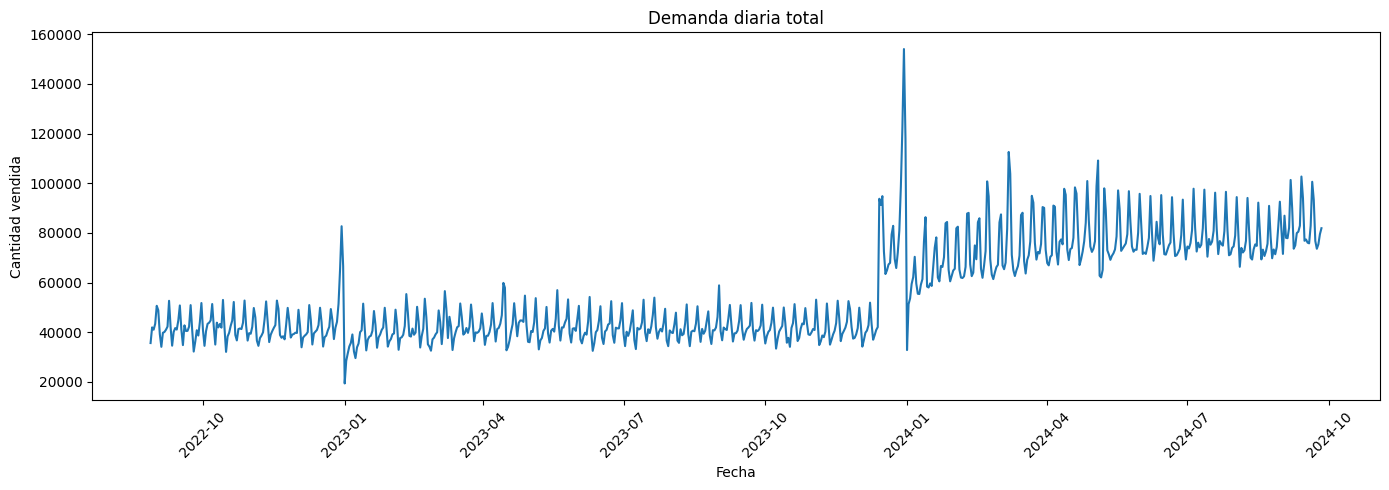

In [36]:

plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand["date"],
    daily_demand["quantity"]
)

plt.title("Demanda diaria total")
plt.xlabel("Fecha")
plt.ylabel("Cantidad vendida")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
sales_model["day_of_week"] = sales_model["date"].dt.day_name()
days_es = {
    "Monday": "Lunes",
    "Tuesday": "Martes",
    "Wednesday": "Miércoles",
    "Thursday": "Jueves",
    "Friday": "Viernes",
    "Saturday": "Sábado",
    "Sunday": "Domingo"
}

sales_model["day_of_week"] = (
    sales_model["date"]
    .dt.day_name()
    .map(days_es)
)

weekly_demand = (
    sales_model
    .groupby("day_of_week")["quantity"]
    .mean()
    .reindex([
        "Lunes",
        "Martes",
        "Miércoles",
        "Jueves",
        "Viernes",
        "Sábado",
        "Domingo"
    ])
)

print(weekly_demand)

day_of_week
Lunes        5.393359
Martes       5.421528
Miércoles    5.514865
Jueves       5.725867
Viernes      6.236799
Sábado       5.858003
Domingo      5.277788
Name: quantity, dtype: float64


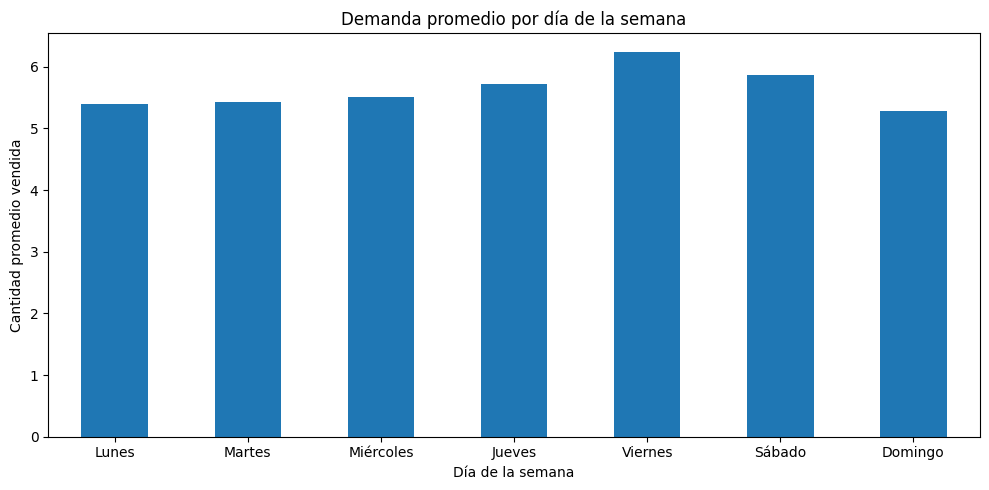

In [38]:
plt.figure(figsize=(10, 5))

weekly_demand.plot(kind="bar")

plt.title("Demanda promedio por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Cantidad promedio vendida")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [39]:
daily_by_weekday = (
    daily_demand.assign(
        day_of_week=daily_demand["date"].dt.day_name().map(days_es)
    )
    .groupby("day_of_week")["quantity"]
    .mean()
    .reindex([
        "Lunes",
        "Martes",
        "Miércoles",
        "Jueves",
        "Viernes",
        "Sábado",
        "Domingo"
    ])
)

print(daily_by_weekday)

day_of_week
Lunes        50015.093587
Martes       51431.701706
Miércoles    53171.998284
Jueves       56852.974560
Viernes      66736.699667
Sábado       59146.245074
Domingo      48658.249092
Name: quantity, dtype: float64


day_of_week
Lunes        50015.093587
Martes       51431.701706
Miércoles    53171.998284
Jueves       56852.974560
Viernes      66736.699667
Sábado       59146.245074
Domingo      48658.249092
Name: quantity, dtype: float64


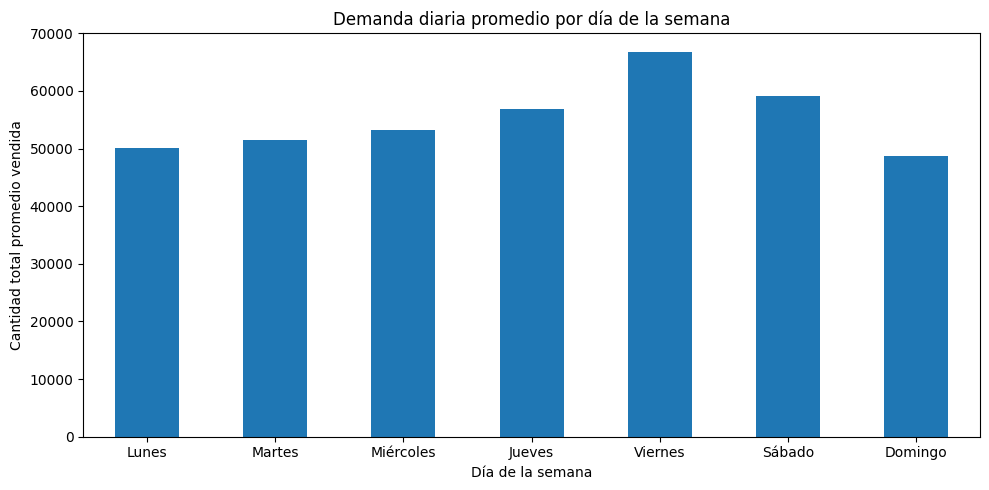

In [40]:
print(daily_by_weekday)

plt.figure(figsize=(10, 5))

daily_by_weekday.plot(kind="bar")

plt.title("Demanda diaria promedio por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Cantidad total promedio vendida")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [41]:
sales_model["day_of_week"]

0          Viernes
1          Viernes
2          Viernes
3          Viernes
4          Viernes
            ...   
7432680     Jueves
7432681     Jueves
7432682     Jueves
7432683     Jueves
7432684     Jueves
Name: day_of_week, Length: 7429061, dtype: object

         date     quantity
0  2022-08-01   161947.719
1  2022-09-01  1260658.287
2  2022-10-01  1306590.733
3  2022-11-01  1253997.243
4  2022-12-01  1386154.072
5  2023-01-01  1165316.091
6  2023-02-01  1145169.274
7  2023-03-01  1318094.224
8  2023-04-01  1292749.837
9  2023-05-01  1299842.681
10 2023-06-01  1257231.653
11 2023-07-01  1283548.424
12 2023-08-01  1280499.195
13 2023-09-01  1280531.310
14 2023-10-01  1280277.961
15 2023-11-01  1257658.749
16 2023-12-01  2100635.721
17 2024-01-01  1983902.447
18 2024-02-01  2085927.528
19 2024-03-01  2400885.680
20 2024-04-01  2364241.840
21 2024-05-01  2456964.945
22 2024-06-01  2327481.891
23 2024-07-01  2449969.778
24 2024-08-01  2402960.918
25 2024-09-01  2146291.709


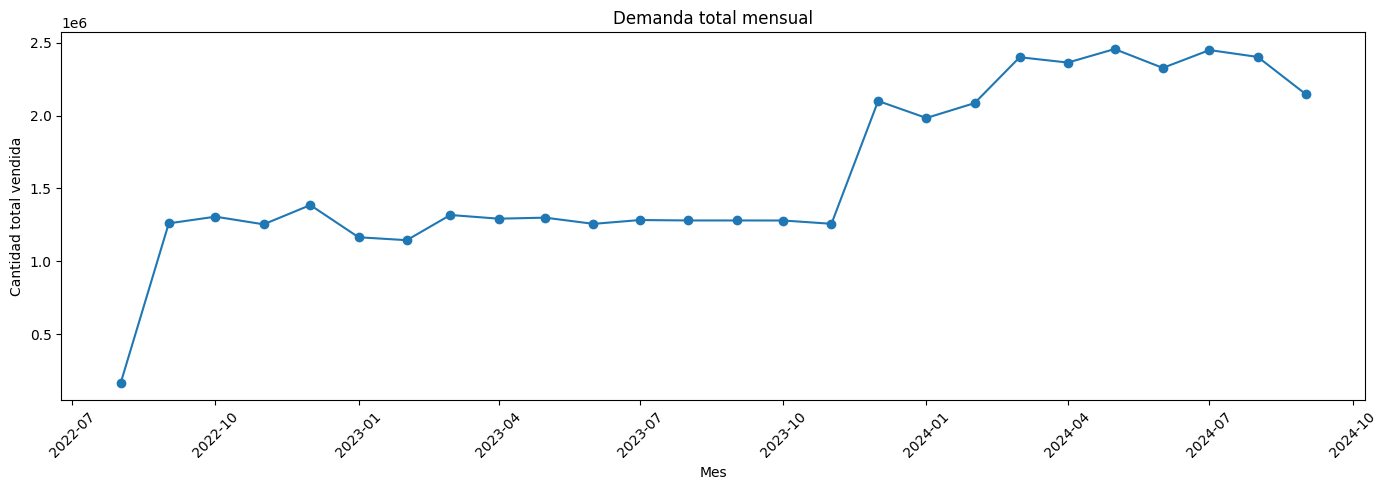

In [42]:
monthly_demand = (
    sales_model
    .groupby(sales_model["date"].dt.to_period("M"))["quantity"]
    .sum()
    .reset_index()
)

monthly_demand["date"] = monthly_demand["date"].dt.to_timestamp()

monthly_demand.head()

print(monthly_demand)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_demand["date"],
    monthly_demand["quantity"],
    marker="o"
)

plt.title("Demanda total mensual")
plt.xlabel("Mes")
plt.ylabel("Cantidad total vendida")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
monthly_demand["year"] = monthly_demand["date"].dt.year
monthly_demand["month"] = monthly_demand["date"].dt.month

monthly_comparison = (
    monthly_demand
    .groupby(["year", "month"])["quantity"]
    .sum()
    .reset_index()
)

print(monthly_comparison)

    year  month     quantity
0   2022      8   161947.719
1   2022      9  1260658.287
2   2022     10  1306590.733
3   2022     11  1253997.243
4   2022     12  1386154.072
5   2023      1  1165316.091
6   2023      2  1145169.274
7   2023      3  1318094.224
8   2023      4  1292749.837
9   2023      5  1299842.681
10  2023      6  1257231.653
11  2023      7  1283548.424
12  2023      8  1280499.195
13  2023      9  1280531.310
14  2023     10  1280277.961
15  2023     11  1257658.749
16  2023     12  2100635.721
17  2024      1  1983902.447
18  2024      2  2085927.528
19  2024      3  2400885.680
20  2024      4  2364241.840
21  2024      5  2456964.945
22  2024      6  2327481.891
23  2024      7  2449969.778
24  2024      8  2402960.918
25  2024      9  2146291.709


         date     quantity  days_in_month  avg_daily_demand
0  2022-08-01   161947.719             31       5224.119968
1  2022-09-01  1260658.287             30      42021.942900
2  2022-10-01  1306590.733             31      42148.088161
3  2022-11-01  1253997.243             30      41799.908100
4  2022-12-01  1386154.072             31      44714.647484
5  2023-01-01  1165316.091             31      37590.841645
6  2023-02-01  1145169.274             28      40898.902643
7  2023-03-01  1318094.224             31      42519.168516
8  2023-04-01  1292749.837             30      43091.661233
9  2023-05-01  1299842.681             31      41930.409065
10 2023-06-01  1257231.653             30      41907.721767
11 2023-07-01  1283548.424             31      41404.787871
12 2023-08-01  1280499.195             31      41306.425645
13 2023-09-01  1280531.310             30      42684.377000
14 2023-10-01  1280277.961             31      41299.289065
15 2023-11-01  1257658.749             3

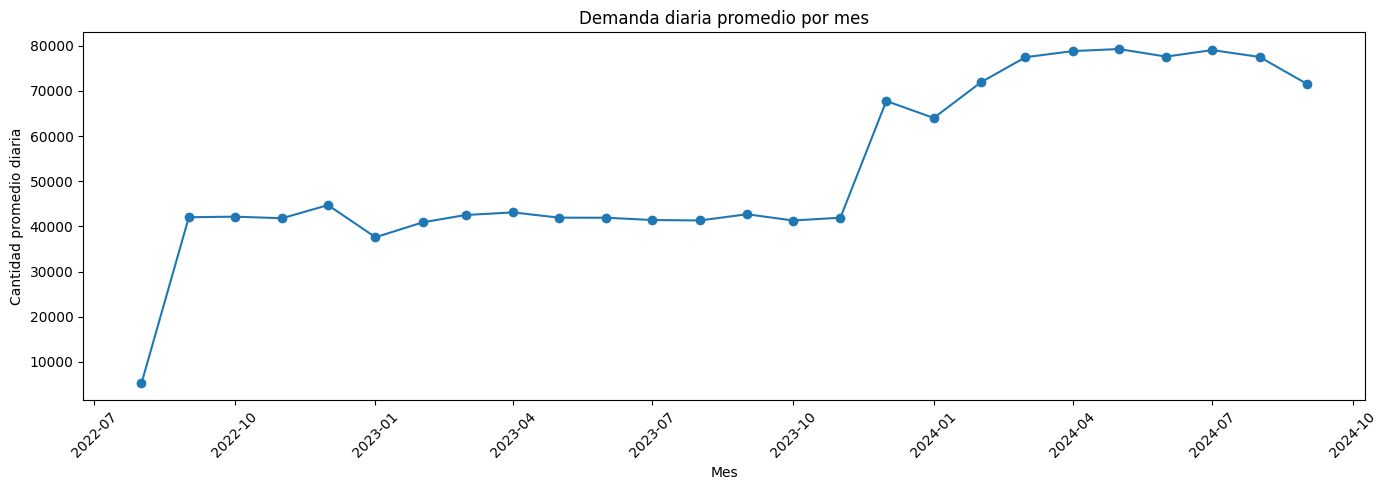

In [44]:
monthly_demand["days_in_month"] = (
    monthly_demand["date"].dt.days_in_month
)

monthly_demand["avg_daily_demand"] = (
    monthly_demand["quantity"] /
    monthly_demand["days_in_month"]
)

print(
    monthly_demand[
        ["date", "quantity", "days_in_month", "avg_daily_demand"]
    ]
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_demand["date"],
    monthly_demand["avg_daily_demand"],
    marker="o"
)

plt.title("Demanda diaria promedio por mes")
plt.xlabel("Mes")
plt.ylabel("Cantidad promedio diaria")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
daily_sales = (
    sales_model
    .groupby(
        ["date", "item_id", "store_id"],
        as_index=False
    )
    .agg(
        quantity=("quantity", "sum"),
        price_base=("price_base", "mean")
    )
)

print("Shape:", daily_sales.shape)
print(daily_sales.head())

print(daily_sales.dtypes)
print("\nValores nulos:")
print(daily_sales.isnull().sum())

print("\nDuplicados:")
print(
    daily_sales.duplicated(
        subset=["date", "item_id", "store_id"]
    ).sum()
)

Shape: (7429061, 5)
        date       item_id  store_id  quantity  price_base
0 2022-08-28  001829cb707d         1       7.0      134.76
1 2022-08-28  001829cb707d         2       1.0      148.00
2 2022-08-28  0022b986c8f0         1       2.0       59.90
3 2022-08-28  00274a69c705         2       1.0       35.90
4 2022-08-28  00274a69c705         3       5.0       35.90
date          datetime64[ns]
item_id               object
store_id               int64
quantity             float64
price_base           float64
dtype: object

Valores nulos:
date          0
item_id       0
store_id      0
quantity      0
price_base    0
dtype: int64

Duplicados:
0


In [46]:
daily_sales["day_of_week"] = daily_sales["date"].dt.dayofweek
daily_sales["day_of_month"] = daily_sales["date"].dt.day
daily_sales["week_of_year"] = (
    daily_sales["date"].dt.isocalendar().week.astype(int)
)
daily_sales["month"] = daily_sales["date"].dt.month
daily_sales["year"] = daily_sales["date"].dt.year
daily_sales["is_weekend"] = (
    daily_sales["day_of_week"] >= 5
).astype(int)

In [47]:
daily_sales = daily_sales.sort_values(
    ["item_id", "store_id", "date"]
).reset_index(drop=True)

group_cols = ["item_id", "store_id"]

daily_sales["lag_1"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .shift(1)
)

daily_sales["lag_7"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .shift(7)
)

daily_sales["lag_14"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .shift(14)
)

daily_sales["lag_28"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .shift(28)
)



In [48]:
daily_sales["rolling_mean_7"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

daily_sales["rolling_mean_28"] = (
    daily_sales
    .groupby(group_cols)["quantity"]
    .transform(
        lambda x: x.shift(1).rolling(28).mean()
    )
)

In [49]:
print(daily_sales.isnull().sum())

daily_sales_model = daily_sales.dropna().copy()

print("Shape antes:", daily_sales.shape)
print("Shape después:", daily_sales_model.shape)

print(daily_sales_model.isnull().sum())

date                     0
item_id                  0
store_id                 0
quantity                 0
price_base               0
day_of_week              0
day_of_month             0
week_of_year             0
month                    0
year                     0
is_weekend               0
lag_1                58005
lag_7               374051
lag_14              697371
lag_28             1258038
rolling_mean_7      374051
rolling_mean_28    1258038
dtype: int64
Shape antes: (7429061, 17)
Shape después: (6171023, 17)
date               0
item_id            0
store_id           0
quantity           0
price_base         0
day_of_week        0
day_of_month       0
week_of_year       0
month              0
year               0
is_weekend         0
lag_1              0
lag_7              0
lag_14             0
lag_28             0
rolling_mean_7     0
rolling_mean_28    0
dtype: int64


In [50]:
print(daily_sales_model.head())
print("\nColumnas:")
print(daily_sales_model.columns.tolist())

print("Shape antes:", daily_sales.shape)
print("Shape después:", daily_sales_model.shape)
print(daily_sales_model.isnull().sum())

         date       item_id  store_id  quantity  price_base  day_of_week  \
50 2022-10-05  001829cb707d         1       3.0      149.90            2   
51 2022-10-06  001829cb707d         1       3.0      149.90            3   
52 2022-10-07  001829cb707d         1       1.0      149.90            4   
53 2022-10-08  001829cb707d         1       4.0      146.67            5   
54 2022-10-09  001829cb707d         1       3.0      149.90            6   

    day_of_month  week_of_year  month  year  is_weekend  lag_1  lag_7  lag_14  \
50             5            40     10  2022           0    5.0    1.0     4.0   
51             6            40     10  2022           0    3.0    1.0     1.0   
52             7            40     10  2022           0    3.0    1.0     5.0   
53             8            40     10  2022           1    1.0    3.0     9.0   
54             9            40     10  2022           1    4.0    2.0     1.0   

    lag_28  rolling_mean_7  rolling_mean_28  
50     7.0

In [51]:
train = daily_sales_model[
    daily_sales_model["date"] < "2024-07-01"
].copy()

test = daily_sales_model[
    daily_sales_model["date"] >= "2024-07-01"
].copy()

print("Train:", train.shape)
print("Test:", test.shape)

print("\nPeriodo train:")
print(train["date"].min(), "hasta", train["date"].max())

print("\nPeriodo test:")
print(test["date"].min(), "hasta", test["date"].max())



Train: (5063980, 17)
Test: (1107043, 17)

Periodo train:
2022-09-25 00:00:00 hasta 2024-06-30 00:00:00

Periodo test:
2024-07-01 00:00:00 hasta 2024-09-26 00:00:00


In [52]:
features = [
    "price_base",
    "store_id",
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month",
    "year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

target = "quantity"

In [53]:
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5063980, 14)
y_train: (5063980,)
X_test: (1107043, 14)
y_test: (1107043,)


In [54]:
print("Train - quantity:")
print(y_train.describe())

print("\nTest - quantity:")
print(y_test.describe())

print("Nulos en X_train:", X_train.isnull().sum().sum())
print("Nulos en X_test:", X_test.isnull().sum().sum())

Train - quantity:
count    5.063980e+06
mean     6.085018e+00
std      2.770382e+01
min      2.000000e-03
25%      1.000000e+00
50%      2.000000e+00
75%      5.000000e+00
max      4.656000e+03
Name: quantity, dtype: float64

Test - quantity:
count    1.107043e+06
mean     5.945800e+00
std      2.793784e+01
min      5.000000e-03
25%      1.000000e+00
50%      2.000000e+00
75%      5.000000e+00
max      2.506000e+03
Name: quantity, dtype: float64
Nulos en X_train: 0
Nulos en X_test: 0


In [55]:
train_sample = train.sample(
    n=min(500_000, len(train)),
    random_state=42
)

X_train_sample = train_sample[features]
y_train_sample = train_sample[target]

print("Muestra de entrenamiento:", X_train_sample.shape)

Muestra de entrenamiento: (500000, 14)


In [56]:
train_sample = train.sample(
    n=min(500_000, len(train)),
    random_state=42
)

X_train_sample = train_sample[features]
y_train_sample = train_sample[target]

print("X_train_sample:", X_train_sample.shape)
print("y_train_sample:", y_train_sample.shape)

X_train_sample: (500000, 14)
y_train_sample: (500000,)


In [57]:
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_sample,
    y_train_sample
)

,n_estimators,50
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [58]:
import time

start_time = time.time()

rf_model.fit(
    X_train_sample,
    y_train_sample
)

end_time = time.time()

print(
    f"Tiempo de entrenamiento: "
    f"{(end_time - start_time) / 60:.2f} minutos"
)

Tiempo de entrenamiento: 0.24 minutos


In [59]:
y_pred = rf_model.predict(X_test)

print("Predicciones generadas:", len(y_pred))
print("Primeras predicciones:", y_pred[:10])

Predicciones generadas: 1107043
Primeras predicciones: [2.55843055 2.48149397 3.1142189  3.51195841 3.60214852 3.08255105
 2.89681386 3.01600587 3.55247297 3.77497364]


In [60]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:,.4f}")
print(f"RMSE: {rmse:,.4f}")
print(f"R²:   {r2:.4f}")

MAE:  2.1682
RMSE: 5.7622
R²:   0.9575


In [61]:
comparison = pd.DataFrame({
    "actual": y_test.values[:20],
    "predicted": y_pred[:20]
})


print("Predicciones:")
print(pd.Series(y_pred).describe())

Predicciones:
count    1.107043e+06
mean     5.975970e+00
std      2.783948e+01
min      1.093711e-01
25%      1.650870e+00
50%      2.509595e+00
75%      4.807709e+00
max      2.440230e+03
dtype: float64


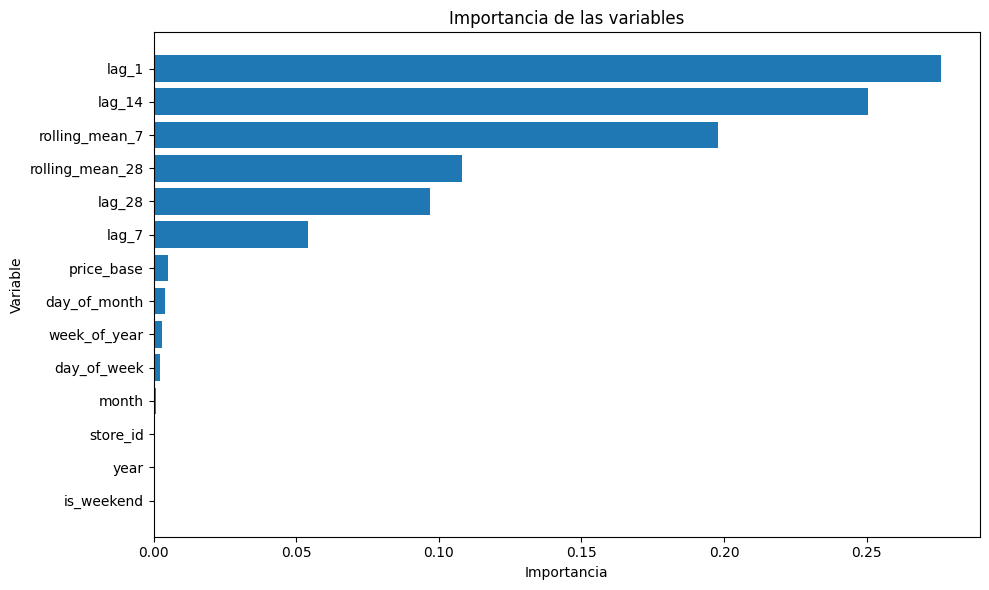

In [62]:
feature_importance = (
    pd.DataFrame({
        "feature": features,
        "importance": rf_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.title("Importancia de las variables")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [63]:
feature_importance = (
    pd.DataFrame({
        "feature": features,
        "importance": rf_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
)

print(feature_importance)

            feature  importance
8             lag_1    0.275945
10           lag_14    0.250401
12   rolling_mean_7    0.197839
13  rolling_mean_28    0.108013
11           lag_28    0.097021
9             lag_7    0.054267
0        price_base    0.005243
3      day_of_month    0.003952
4      week_of_year    0.002868
2       day_of_week    0.002171
5             month    0.000946
1          store_id    0.000627
6              year    0.000391
7        is_weekend    0.000316


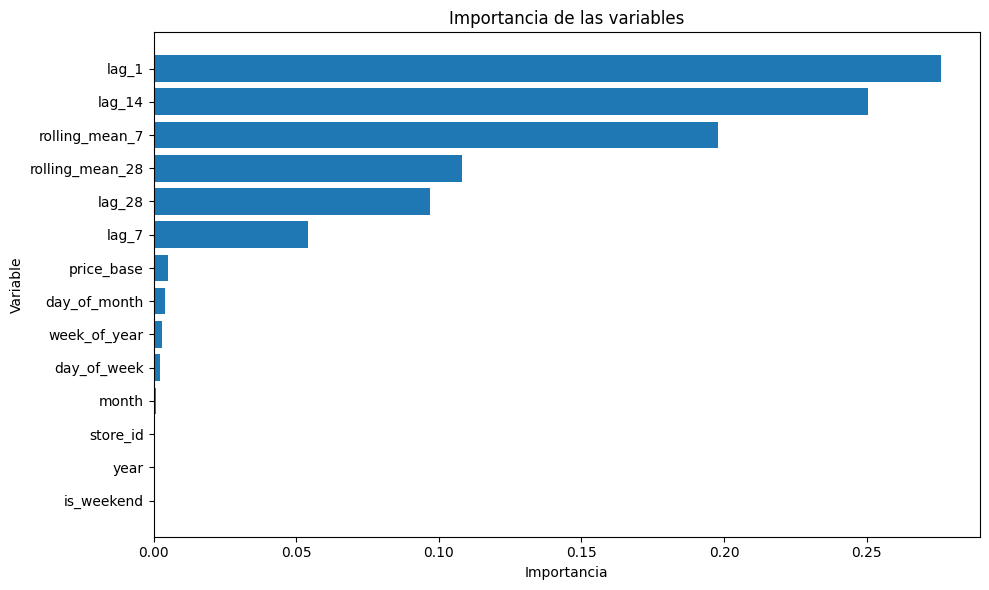

In [64]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.title("Importancia de las variables")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

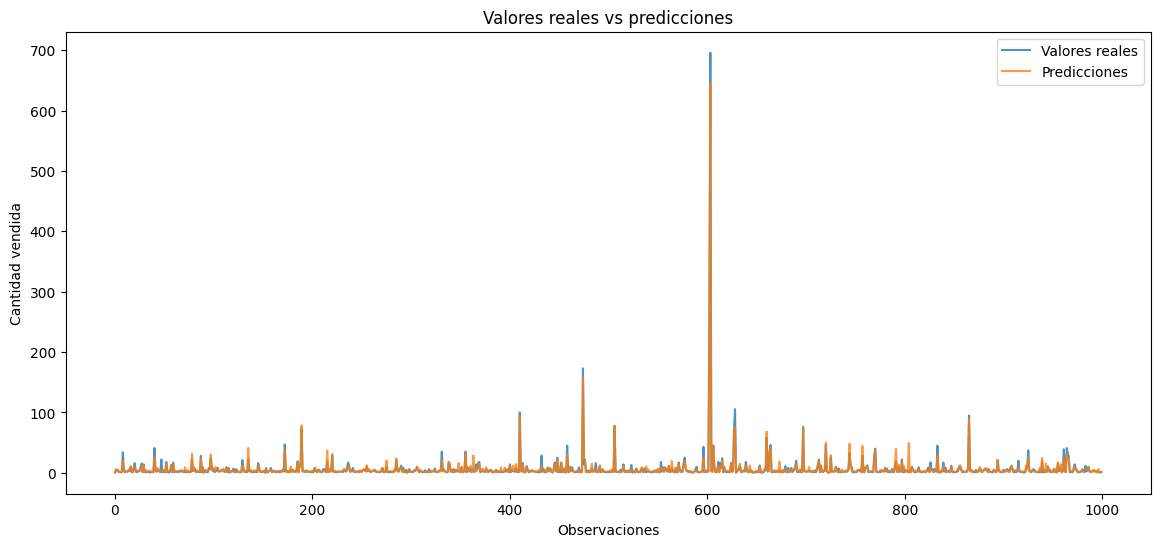

In [65]:
comparison = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred
})

comparison_sample = comparison.sample(
    n=min(1000, len(comparison)),
    random_state=42
).sort_index()

plt.figure(figsize=(14, 6))

plt.plot(
    comparison_sample["actual"].values,
    label="Valores reales",
    alpha=0.8
)

plt.plot(
    comparison_sample["predicted"].values,
    label="Predicciones",
    alpha=0.8
)

plt.title("Valores reales vs predicciones")
plt.xlabel("Observaciones")
plt.ylabel("Cantidad vendida")
plt.legend()
plt.show()

El modelo Random Forest obtuvo un MAE de 2.1682, un RMSE de 5.7622 y un R² de 0.9575 en el conjunto de prueba. La comparación entre valores reales y predicciones muestra que el modelo reproduce razonablemente bien el comportamiento de la demanda y captura buena parte de sus fluctuaciones. El análisis de importancia de variables también reveló que los registros históricos de ventas y los promedios móviles son los principales predictores. Aunque se observan algunas diferencias en los valores extremos, los resultados muestran un desempeño prometedor. Sin embargo, deben interpretarse considerando las limitaciones de la construcción de las variables temporales y la representación de los días sin ventas.

Conclusiones generales

En este proyecto desarrollé un flujo de trabajo de análisis y predicción de ventas utilizando datos históricos de un entorno retail.

Inicialmente, realicé un análisis exploratorio para comprender la estructura de los datos, identificar inconsistencias y evaluar el comportamiento de las ventas. Posteriormente, llevé a cabo un proceso de limpieza, eliminando registros con cantidades no válidas y valores de precio negativos.

Durante la etapa de ingeniería de características, construí variables temporales, indicadores de calendario, valores históricos de ventas (lags) y promedios móviles para representar los patrones de demanda de cada producto y tienda.

Finalmente, entrené un modelo Random Forest Regressor, utilizando una división temporal para evaluar su capacidad predictiva sobre datos posteriores al periodo de entrenamiento.

El modelo obtuvo los siguientes resultados:

MAE: 2.1682

RMSE: 5.7622

R²: 0.9575

El análisis de importancia de variables mostró que el historial de ventas, especialmente las ventas del día anterior (lag_1), de hace 14 días (lag_14) y el promedio móvil de 7 días (rolling_mean_7), son los principales predictores del modelo.

En conclusión, este proyecto permitió construir un modelo de predicción de demanda que demuestra resultados prometedores y evidencia la importancia del comportamiento histórico de las ventas para anticipar necesidades futuras. También permitió aplicar conocimientos de análisis exploratorio, limpieza de datos, ingeniería de características, modelado predictivo y evaluación de modelos.

Como oportunidad de mejora, se podría implementar una estructura de datos con días sin ventas explícitos y evaluar modelos adicionales para comparar su desempeño.